# `seg.assign_bins` vs the real `bin2cell` package

Astrolabe's `seg.assign_bins` reimplements bin2cell's 3-tier core/expansion/contested bin classification (Polanski et al. 2024, *Bioinformatics*, doi:10.1093/bioinformatics/btae546) from scratch, avoiding a dependency on the `bin2cell` package and its dependency tree. This notebook validates it against the real `bin2cell.bin_to_cell` on identical candidate cell polygons, produced here by `segment_cellpose` (an explicitly documented valid input source for `assign_bins`; `stardist`, the originally planned segmenter, cannot install on Python 3.12).

**Structural caveat**: `assign_bins` classifies bins in three ordered tiers (core, then unambiguous expansion, then contested), but this notebook's hand-built reference collapses the first two into one buffered-polygon single-hit pass with no separate core tier -- so the two tools can disagree about which bins are even unambiguous before any tie-break logic runs. This structural difference, not the tie-break rule itself, is the main remaining source of disagreement below. `assign_bins` also has no public per-bin label (only aggregated `X`/`obs['n_bins']`), so the comparison is per-cell aggregates, not a bin-level match.

In [1]:
import logging
logging.basicConfig(level=logging.INFO)

import time
import numpy as np
import astrolabe as ab
import bin2cell as b2c


INFO:astrolabe.pl._theme:Registered bundled Inter font files with matplotlib


INFO:astrolabe.pl._theme:astrolabe plot theme set to 'light'


## Dataset

`ab.datasets.visium_hd()` -- the Mouse Small Intestine Visium HD run with no native on-board segmentation (Space Ranger 3.0.0), the exact scenario `assign_bins`/`segment_bin2cell` targets. Segmentation is restricted to a small `region_um` window of the H&E image to keep this notebook fast.

In [2]:
mdata = ab.datasets.visium_hd()
bins_adata = mdata["visium_hd_bins"]
coords = bins_adata.obsm["spatial"]
print(f"{bins_adata.n_obs} bins, extent x=[{coords[:,0].min():.0f}, {coords[:,0].max():.0f}] "
      f"y=[{coords[:,1].min():.0f}, {coords[:,1].max():.0f}] um")

cx, cy = coords[:, 0].mean(), coords[:, 1].mean()
half = 200.0  # 400 x 400 um window
region_um = (cx - half, cy - half, cx + half, cy + half)

# Materialized once, then reused for *both* tools below -- assign_bins and
# bin_to_cell should classify the identical set of bins, not two
# differently-scoped ones. `inplace=False` is required here: load_bin_counts
# defaults to inplace=True (mutate + return None), matching scanpy's own
# in-place convention.
region_bins = ab.pp.load_bin_counts(bins_adata, region_um=region_um, inplace=False)
region_bins


INFO:astrolabe.io._visium_hd:Reading Visium HD run 'visium_hd' from C:\Users\Austin\PycharmProjects\astrolabe\benchmarks\bin2cell\.astrolabe_cache\datasets\visium_hd\outs


C:\Users\Austin\PycharmProjects\astrolabe\astrolabe\io\_visium_hd.py:203: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  bin_adata = ad.AnnData(


C:\Users\Austin\PycharmProjects\astrolabe\benchmarks\bin2cell\.venv\Lib\site-packages\mudata\_core\mudata.py:1471: UserWarning: var_names are not unique. To make them unique, call `.var_names_make_unique`.
  self._update_attr("var", axis=0, join_common=join_common)


INFO:astrolabe.io._visium_hd:Loaded 5479660 bins × 19059 features (lazy — X not materialized; pixel_size=0.2738 µm)


INFO:astrolabe.io._he:Reading H&E 'Visium_HD_Mouse_Small_Intestine_tissue_image' from C:\Users\Austin\PycharmProjects\astrolabe\benchmarks\bin2cell\.astrolabe_cache\datasets\visium_hd\outs\Visium_HD_Mouse_Small_Intestine_tissue_image.btf


...

C:\Users\Austin\PycharmProjects\astrolabe\benchmarks\bin2cell\.venv\Lib\site-packages\mudata\_core\mudata.py:1471: UserWarning: var_names are not unique. To make them unique, call `.var_names_make_unique`.
  self._update_attr("var", axis=0, join_common=join_common)


INFO:astrolabe.io._visium_hd:Attached H&E image from C:\Users\Austin\PycharmProjects\astrolabe\benchmarks\bin2cell\.astrolabe_cache\datasets\visium_hd\outs\Visium_HD_Mouse_Small_Intestine_tissue_image.btf (pixel-aligned to bins)


5479660 bins, extent x=[43, 6422] y=[-5, 6573] um


C:\Users\Austin\PycharmProjects\astrolabe\astrolabe\pp\_visium_hd.py:213: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  target = adata if inplace else adata.copy()
C:\Users\Austin\PycharmProjects\astrolabe\astrolabe\pp\_visium_hd.py:216: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  target._inplace_subset_obs(bin_mask)
C:\Users\Austin\PycharmProjects\astrolabe\astrolabe\pp\_visium_hd.py:216: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  target._inplace_subset_obs(bin_mask)
INFO:astrolabe.pp._visium_hd:load_bin_counts: reading 26816 bins × 19059 genes from C:\Users\Austin\PycharmProjects\astrolabe\benchmarks\bin2cell\.astrolabe_cache\datasets\visium_hd\outs\binned_outputs\square_002um\filtered_feature_bc_matrix.h5


AnnData object with n_obs × n_vars = 26816 × 19059
    obs: 'array_row', 'array_col', 'in_tissue'
    var: 'gene_id', 'gene_name', 'feature_type'
    uns: 'spatial', 'astrolabe_schema_version'
    obsm: 'spatial'
    layers: None (.X)

## A shared segmentation, for a fair comparison

One `segment_cellpose` call produces the candidate cell polygons both
tools bin-assign against — any disagreement below reflects the
bin-assignment logic itself, not different upstream segmentations.


In [3]:
cell_seg = ab.seg.segment_cellpose(
    mdata["he"], region_um=region_um, pretrained_model="cyto2", diameter=12.0,
)
cell_seg.n_obs


INFO:astrolabe.seg._segment:segment_cellpose: restricting to region_um=(np.float32(2837.5315), np.float32(2802.5208), np.float32(3237.5315), np.float32(3202.5208)) → pixel bbox rows=10237:11699 cols=10364:11827


INFO:astrolabe.seg._segment:segment_cellpose: loading channel 0 from C:\Users\Austin\PycharmProjects\astrolabe\benchmarks\bin2cell\.astrolabe_cache\datasets\visium_hd\outs\Visium_HD_Mouse_Small_Intestine_tissue_image.btf


INFO:cellpose.core:>>>> using CPU


INFO:cellpose.core:>>>> using CPU


INFO:cellpose.models:>>>> loading model C:\Users\Austin\.cellpose\models\cpsam_v2


...

C:\Users\Austin\PycharmProjects\astrolabe\benchmarks\bin2cell\.venv\Lib\site-packages\cellpose\dynamics.py:541: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\Context.cpp:823.)
  coo = torch.sparse_coo_tensor(pt, torch.ones(pt.shape[1], device=pt.device, dtype=torch.int),


INFO:astrolabe.seg._segment:segment_cellpose: found 1235 cells


INFO:astrolabe.seg._segment:Converting 1235 segmented cells to AnnData


C:\Users\Austin\PycharmProjects\astrolabe\astrolabe\seg\_segment.py:418: ExperimentalFeatureWarning: Support for Awkward Arrays is currently experimental. Behavior may change in the future. Please report any issues you may encounter!
  adata.obsm["cell_boundaries"] = ak.Array(polys_um)


1235

## Astrolabe: `seg.assign_bins`

Runs on `region_bins` (not the full, potentially slide-wide `bins_adata`)
so this stays fast and so both tools see the identical bin population.


In [4]:
expand_um = 4.0
_t0 = time.perf_counter()
cells_astro = ab.seg.assign_bins(region_bins, cell_seg, expand_um=expand_um, tie_break="pca", inplace=False)
t_astro_s = time.perf_counter() - _t0
print(f"astrolabe runtime: {t_astro_s:.4f}s")
cells_astro.obs[["n_bins"]].describe()


INFO:astrolabe.seg._bin2cell:assign_bins: 26816 bins, 1235 candidate cells


INFO:astrolabe.seg._bin2cell:assign_bins: 4415 core bins assigned


INFO:astrolabe.seg._bin2cell:assign_bins: 5920 unambiguous-expansion bins, 7475 contested bins, 9006 unassigned


C:\Users\Austin\PycharmProjects\astrolabe\astrolabe\seg\_bin2cell.py:424: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  new = ad.AnnData(
C:\Users\Austin\PycharmProjects\astrolabe\astrolabe\seg\_bin2cell.py:431: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  new = new[keep_mask].copy()
INFO:astrolabe.seg._bin2cell:assign_bins: 1232 / 1235 cells retained (min_bin_counts=1); 17810 total bins assigned (66.4%)


astrolabe runtime: 5.6504s


,n_bins
count,1232.000000
mean,14.456169
std,7.657028
min,1.000000
25%,9.000000
50%,14.000000
75%,19.000000
max,74.000000


## Reference: `bin2cell.bin_to_cell`

`bin_to_cell` expects an integer object-label column in `obs` (0 = unassigned) rather than polygons, so `cell_seg`'s polygons are rasterized onto the bin grid first, using the same `expand_um` buffer as the `assign_bins` call above. Contested bins (claimed by more than one candidate) are resolved with the same PCA-transcriptional-similarity tie-break astrolabe's own `tie_break='pca'` uses, so both tools' tie-break logic is directly comparable.

In [5]:
import geopandas as gpd
from shapely.geometry import Point, Polygon
from sklearn.decomposition import PCA

_t0 = time.perf_counter()  # includes rasterization -- a real cost bin2cell users pay that
                            # astrolabe's polygon-native assign_bins never needs to.

region_bins = region_bins.copy()  # bin_to_cell writes obs columns below

cell_polys = [Polygon(p) for p in cell_seg.obsm["cell_boundaries"]]
centroids = np.array([[poly.centroid.x, poly.centroid.y] for poly in cell_polys])
expanded_polys = [poly.buffer(expand_um) for poly in cell_polys]  # expand_um set alongside assign_bins, above
cell_gdf = gpd.GeoDataFrame({"object_id": np.arange(1, len(cell_polys) + 1)}, geometry=expanded_polys)

bin_pts = gpd.GeoDataFrame(
    {"bin_idx": np.arange(region_bins.n_obs)},
    geometry=[Point(xy) for xy in region_bins.obsm["spatial"]],
)
joined = gpd.sjoin(bin_pts, cell_gdf, how="left", predicate="within")

hit_counts = joined.groupby("bin_idx").size()
single_idx = hit_counts[hit_counts == 1].index
contested_idx = hit_counts[hit_counts > 1].index

labels = np.zeros(region_bins.n_obs, dtype=int)
single = joined[joined["bin_idx"].isin(single_idx)]
labels[single["bin_idx"].to_numpy()] = single["object_id"].fillna(0).to_numpy().astype(int)

bin_coords = region_bins.obsm["spatial"]
X_bins_ref = region_bins.X
if hasattr(X_bins_ref, "toarray"):
    X_bins_ref = X_bins_ref.toarray()
X_bins_ref = np.asarray(X_bins_ref, dtype=np.float64)
n_cells_ref = len(cell_polys)


def _normalize_rows(rows: np.ndarray, target_sum: float) -> np.ndarray:
    # Mirrors astrolabe's own astrolabe.seg._bin2cell._normalize_rows:
    # total-count normalize to a fixed, shared target_sum, then log1p --
    # the fixed target keeps a single contested bin's own PCA-space
    # transform comparable to the fitted provisional-cell-profile space.
    rows = np.atleast_2d(rows).astype(np.float64)
    totals = rows.sum(axis=1, keepdims=True)
    totals_safe = np.where(totals > 0, totals, 1.0)
    return np.log1p(rows / totals_safe * target_sum)


# Provisional per-cell profile: sum of only the unambiguous (single-hit)
# bins already assigned above -- built before any contested bin is
# resolved, same as astrolabe's own `provisional_X`.
provisional = np.zeros((n_cells_ref, X_bins_ref.shape[1]), dtype=np.float64)
single_bin_idx = single["bin_idx"].to_numpy()
single_obj_id = single["object_id"].fillna(0).to_numpy().astype(int)
valid_single = single_obj_id > 0
np.add.at(provisional, single_obj_id[valid_single] - 1, X_bins_ref[single_bin_idx[valid_single]])
profile_totals = provisional.sum(axis=1)
eligible_mask = profile_totals > 0

pca_ref = None
cell_pca_row = None
eligible_pca = None
target_sum = 1.0
if len(contested_idx) > 0 and eligible_mask.sum() >= 2:
    eligible_cell_idx = np.where(eligible_mask)[0]
    target_sum = float(np.median(profile_totals[eligible_mask]))
    normed_profiles = _normalize_rows(provisional[eligible_mask], target_sum)
    n_components = min(15, normed_profiles.shape[0] - 1, normed_profiles.shape[1])
    if n_components >= 1:
        pca_ref = PCA(n_components=n_components)
        eligible_pca = pca_ref.fit_transform(normed_profiles)
        cell_pca_row = -np.ones(n_cells_ref, dtype=np.int64)
        cell_pca_row[eligible_cell_idx] = np.arange(len(eligible_cell_idx))

for bidx in contested_idx:
    candidates = sorted(set(joined.loc[joined["bin_idx"] == bidx, "object_id"].dropna().astype(int).tolist()))
    cand_zero = [c - 1 for c in candidates]
    eligible_candidates = (
        candidates if pca_ref is not None and all(cell_pca_row[c] >= 0 for c in cand_zero) else []
    )
    if eligible_candidates:
        bin_normed = _normalize_rows(X_bins_ref[bidx], target_sum)
        bin_pca = pca_ref.transform(bin_normed)
        cand_rows = [cell_pca_row[c - 1] for c in eligible_candidates]
        dists = np.linalg.norm(eligible_pca[cand_rows] - bin_pca, axis=1)
        winner = eligible_candidates[int(np.argmin(dists))]
    else:
        cand_centroids = centroids[np.array(candidates) - 1]
        dists = np.linalg.norm(cand_centroids - bin_coords[bidx], axis=1)
        winner = candidates[int(np.argmin(dists))]
    labels[bidx] = winner

region_bins.obs["labels_expanded"] = labels
region_bins.obs["array_row"] = region_bins.obs.get("array_row", 0)
region_bins.obs["array_col"] = region_bins.obs.get("array_col", 0)

# bin_to_cell reads uns['spatial'][library]['scalefactors']['spot_diameter_fullres']
# internally -- a Space Ranger / scanpy convention astrolabe's own uns['spatial']
# (ImageSpec/BinMatrixSpec-based) doesn't populate. The value only affects
# cosmetic downstream metadata bin2cell itself attaches, not which bins get
# assigned to which cell, so any reasonable placeholder (here: 2um bin pitch,
# in the same px units Space Ranger would report) satisfies the KeyError
# without affecting the comparison below.
library = list(region_bins.uns["spatial"].keys())[0]
region_bins.uns["spatial"][library].setdefault("scalefactors", {})["spot_diameter_fullres"] = 2.0

cells_ref = b2c.bin_to_cell(region_bins, labels_key="labels_expanded", spatial_keys=["spatial"])
t_ref_s = time.perf_counter() - _t0
print(f"reference runtime (rasterization + bin_to_cell): {t_ref_s:.4f}s")
cells_ref.obs[["bin_count"]].describe()


C:\Users\Austin\AppData\Local\Temp\ipykernel_64516\438205162.py:8: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  region_bins = region_bins.copy()  # bin_to_cell writes obs columns below


reference runtime (rasterization + bin_to_cell): 7.5481s


C:\Users\Austin\PycharmProjects\astrolabe\benchmarks\bin2cell\.venv\Lib\site-packages\bin2cell\bin2cell.py:1578: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  cell_adata = ad.AnnData(X, var = adata.var)


,bin_count
count,1232.000000
mean,14.456169
std,7.635568
min,1.000000
25%,9.000000
50%,13.000000
75%,19.000000
max,74.000000


## Agreement


1229 / 1232 astrolabe cells have a matching bin2cell object
Pearson r (bin count per cell) = 0.6655, exact match rate = 10.8%
Runtime: astrolabe 5.6504s vs bin2cell 7.5481s (1.3x astrolabe faster) -- bin2cell's number includes rasterizing the shared polygons to a bin-label column, a step astrolabe's polygon-native assign_bins skips entirely.


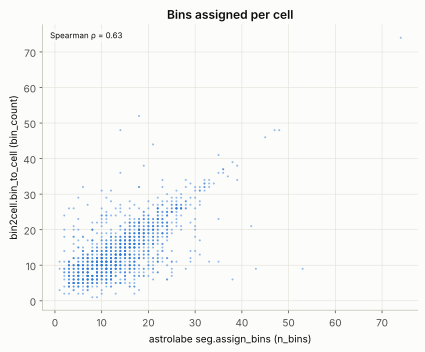

In [6]:
astro_by_id = cells_astro.obs.set_index(np.arange(1, cells_astro.n_obs + 1))["n_bins"]
ref_by_id = cells_ref.obs.set_index(cells_ref.obs["object_id"].astype(int))["bin_count"]
common_ids = sorted(set(astro_by_id.index) & set(ref_by_id.index))
print(f"{len(common_ids)} / {cells_astro.n_obs} astrolabe cells have a matching bin2cell object")

n_bins_astro = astro_by_id.loc[common_ids].to_numpy()
n_bins_ref = ref_by_id.loc[common_ids].to_numpy()

r = np.corrcoef(n_bins_astro, n_bins_ref)[0, 1]
exact_match = np.mean(n_bins_astro == n_bins_ref)
print(f"Pearson r (bin count per cell) = {r:.4f}, exact match rate = {exact_match:.1%}")
print(f"Runtime: astrolabe {t_astro_s:.4f}s vs bin2cell {t_ref_s:.4f}s "
      f"({max(t_astro_s, t_ref_s) / min(t_astro_s, t_ref_s):.1f}x astrolabe {'faster' if t_astro_s < t_ref_s else 'slower'}) -- "
      f"bin2cell's number includes rasterizing the shared polygons to a bin-label column, "
      f"a step astrolabe's polygon-native assign_bins skips entirely.")

panel = ab.pl.scatter(
    cell_seg, x=n_bins_astro, y=n_bins_ref, annotate_corr=True,
    xlabel="astrolabe seg.assign_bins (n_bins)", ylabel="bin2cell.bin_to_cell (bin_count)",
    title="Bins assigned per cell",
)
panel.show()


## Interpretation

`bin2cell.bin_to_cell` itself has no tie-break logic -- it simply sums whatever bins a caller's label column already assigns to each object, so all of the tie-breaking above happens before it's called. With a matching PCA tie-break on both sides, most of the remaining disagreement traces back to the structural tiering difference noted at the top: astrolabe's three ordered tiers vs. this notebook's collapsed two-pass reference.